# CNN Chest X-Ray Classifier — Solved Notebook

Every `# TODO` of the starter notebook is completed below, task by task, following the
exercise brief (preprocess → split → weight → build → train → evaluate).

**Dataset:** [Chest X-Ray Images (Pneumonia)](https://www.kaggle.com/datasets/paultimothymooney/chest-xray-pneumonia) — binary, NORMAL vs PNEUMONIA.

> **Which data is this run on?** The switch `USE_SYNTHETIC` in Step 0 chooses.
> `True` builds a small fake dataset with the same folder layout and the same quirks
> (imbalance, varying sizes, RGB + grayscale) so the notebook runs in minutes with no download.
> **For your real submission set it to `False`** after downloading the Kaggle data
> (`bash scripts/download_data.sh`, see `data/README.md`) and re-run everything — the numbers
> in a synthetic run say nothing about real X-rays.

## Step 0 — Setup

In [1]:
import os, sys
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

from sklearn.model_selection import train_test_split
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

import tensorflow as tf
from tensorflow.keras import layers, models
from tensorflow.keras.callbacks import EarlyStopping

SEED = 42
np.random.seed(SEED)
tf.random.set_seed(SEED)
print("TensorFlow version:", tf.__version__)

# ---- choose the data: synthetic demo (fast) or the real Kaggle dataset -----------
USE_SYNTHETIC = True        # <-- set to False for the real dataset

if USE_SYNTHETIC:
    sys.path.insert(0, os.path.abspath(".."))          # so we can import src/
    from src.synthetic import generate_synthetic_dataset
    DATA_ROOT = "../data/synthetic_chest_xray"
    generate_synthetic_dataset(DATA_ROOT, scale=1.0, seed=SEED)   # no-op if it already exists
else:
    DATA_ROOT = "../data/chest_xray_data/chest_xray"

CLASSES = ["NORMAL", "PNEUMONIA"]     # label 0 and label 1
print("Data ready at:", DATA_ROOT)

I0000 00:00:1791883629.487875     980 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1791883629.521278     980 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI AVX512_BF16 AVX512_FP16 AVX_VNNI AMX_TILE AMX_INT8 AMX_BF16 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


I0000 00:00:1791883630.598889     980 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


TensorFlow version: 2.21.0


Data ready at: ../data/synthetic_chest_xray


## Task 1 — Inspect Before You Touch Anything

Every later decision (splitting, preprocessing, weighting, evaluating) depends on two facts about
the raw data: how **imbalanced** the classes are, and how **inconsistent** the images are.

In [2]:
# Task 1a: count images per class for 'train' and 'test'
for split in ["train", "test"]:
    print(f"--- {split} ---")
    for cls in CLASSES:
        path = os.path.join(DATA_ROOT, split, cls)
        count = len(os.listdir(path))
        print(f"  {cls}: {count} images")

--- train ---
  NORMAL: 110 images
  PNEUMONIA: 330 images
--- test ---
  NORMAL: 45 images
  PNEUMONIA: 75 images


In [3]:
# Task 1b: size and colour mode of 5 sample images per class
print(f"{'Class':<10} {'Size':<12} {'Mode'}")
for cls in CLASSES:
    cls_dir = os.path.join(DATA_ROOT, "train", cls)
    for f in sorted(os.listdir(cls_dir))[:5]:
        with Image.open(os.path.join(cls_dir, f)) as im:
            print(f"{cls:<10} {str(im.size):<12} {im.mode}")

# Scan *every* train image to be sure (5 samples can hide inconsistency)
sizes, modes = set(), {}
for cls in CLASSES:
    cls_dir = os.path.join(DATA_ROOT, "train", cls)
    for f in os.listdir(cls_dir):
        with Image.open(os.path.join(cls_dir, f)) as im:
            sizes.add(im.size)
            modes[im.mode] = modes.get(im.mode, 0) + 1
print(f"\nDistinct image sizes in train: {len(sizes)}")
print(f"Colour modes in train: {modes}")

Class      Size         Mode
NORMAL     (128, 128)   RGB
NORMAL     (197, 197)   L
NORMAL     (163, 163)   L
NORMAL     (139, 139)   L
NORMAL     (138, 138)   RGB
PNEUMONIA  (148, 148)   L
PNEUMONIA  (178, 178)   L
PNEUMONIA  (213, 213)   RGB
PNEUMONIA  (191, 191)   L
PNEUMONIA  (185, 185)   L

Distinct image sizes in train: 99
Colour modes in train: {'L': 290, 'RGB': 150}


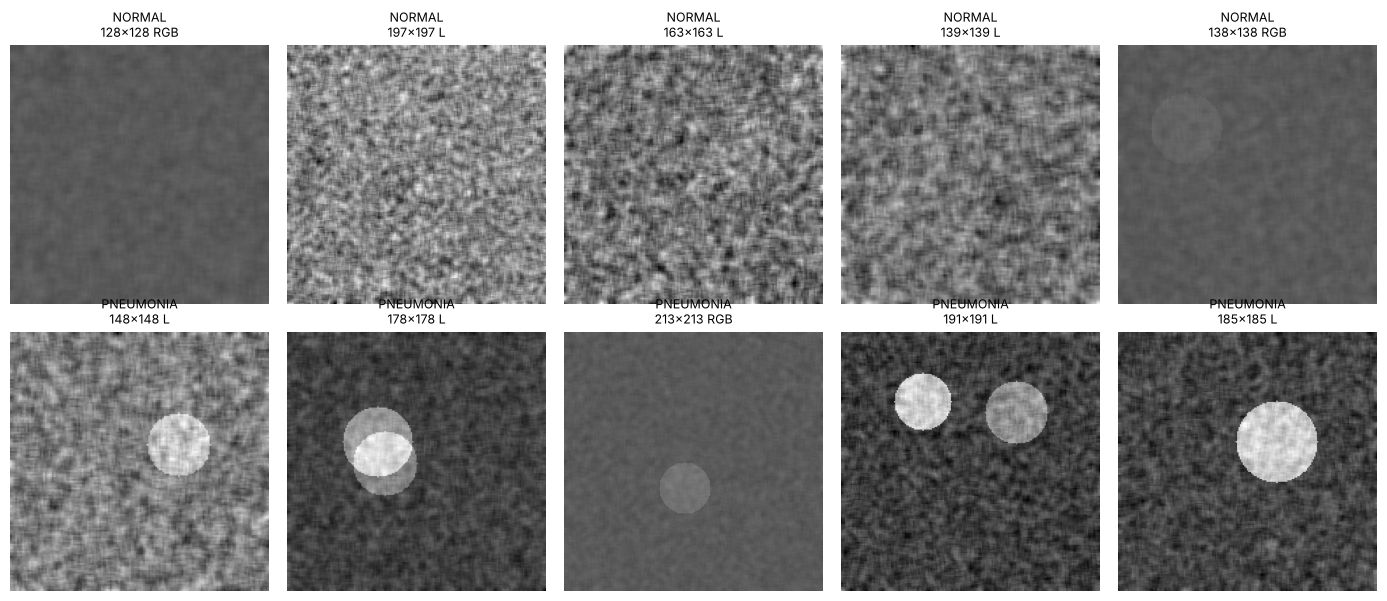

In [4]:
# Task 1c: 2x5 grid, top row NORMAL, bottom row PNEUMONIA
fig, axes = plt.subplots(2, 5, figsize=(14, 6))
for row, cls in enumerate(CLASSES):
    cls_dir = os.path.join(DATA_ROOT, "train", cls)
    for col, f in enumerate(sorted(os.listdir(cls_dir))[:5]):
        with Image.open(os.path.join(cls_dir, f)) as im:
            axes[row, col].imshow(im, cmap="gray" if im.mode == "L" else None)
            axes[row, col].set_title(f"{cls}\n{im.size[0]}x{im.size[1]} {im.mode}", fontsize=9)
            axes[row, col].axis("off")
plt.tight_layout()
plt.show()

In [5]:
# Task 1d: class imbalance ratio in the TRAIN set (stored for reuse in Task 3)
n_normal = len(os.listdir(os.path.join(DATA_ROOT, "train", "NORMAL")))
n_pneumonia = len(os.listdir(os.path.join(DATA_ROOT, "train", "PNEUMONIA")))
imbalance_ratio = n_pneumonia / n_normal

print(f"NORMAL:    {n_normal}")
print(f"PNEUMONIA: {n_pneumonia}")
print(f"Imbalance ratio (PNEUMONIA / NORMAL): {imbalance_ratio:.2f}x")

NORMAL:    110
PNEUMONIA: 330
Imbalance ratio (PNEUMONIA / NORMAL): 3.00x


**Checkpoint — what the output above shows:** PNEUMONIA has roughly **3×** as many training images as
NORMAL, and image sizes are **not** consistent (many distinct sizes) while colour modes are **mixed**
(grayscale `L` and `RGB`). So we must resize and convert to one colour mode before anything can be
batched, and plain accuracy will be misleading.

## Task 2 — Build a Proper Train/Validation Split

* The provided `val/` folder has only 16 images — one image changes any metric by > 6 points, so it
  cannot be trusted for decisions such as when to stop training. **We ignore it.**
* A **stratified** split keeps the same class ratio in both parts, so validation is representative.
* `test/` stays untouched until the very end — it is the only honest estimate of real-world performance.

In [6]:
# Task 2a: parallel lists of paths and labels (0 = NORMAL, 1 = PNEUMONIA)
all_paths, all_labels = [], []
for label, cls in enumerate(CLASSES):
    cls_dir = os.path.join(DATA_ROOT, "train", cls)
    for f in sorted(os.listdir(cls_dir)):
        all_paths.append(os.path.join(cls_dir, f))
        all_labels.append(label)

print(f"Total train-folder images collected: {len(all_paths)}")

Total train-folder images collected: 440


In [7]:
# Task 2b: stratified 85 / 15 split
train_paths, val_paths, train_labels, val_labels = train_test_split(
    all_paths, all_labels, test_size=0.15, stratify=all_labels, random_state=SEED
)

print(f"Train: {len(train_paths)} images | Val: {len(val_paths)} images")
tr_ratio = train_labels.count(1) / len(train_labels)
va_ratio = val_labels.count(1) / len(val_labels)
print(f"Train PNEUMONIA ratio: {tr_ratio:.3f}  |  Val PNEUMONIA ratio: {va_ratio:.3f}")
assert abs(tr_ratio - va_ratio) < 0.01, "stratification should keep the ratios almost identical"
print("Ratios match -> stratification worked.")

Train: 374 images | Val: 66 images
Train PNEUMONIA ratio: 0.751  |  Val PNEUMONIA ratio: 0.742
Ratios match -> stratification worked.


## Task 3 — Preprocessing Pipeline

Order matters:

1. **Resize** every image to a fixed size — networks need constant-shape tensors to batch.
2. **Convert to one colour mode** (grayscale) — X-rays carry no colour signal; drops 3× the compute.
3. **Normalize to [0, 1]** — well-behaved gradients.
4. **Augment training data only** — validation/test must mirror real-world data, or their scores become meaningless.
5. **Class weights from the *original* counts**, before augmentation — augmentation does not change how common each class really is.

In [8]:
IMG_SIZE = 150      # the exercise suggests 150x150
BATCH_SIZE = 32

def load_and_preprocess(path, augment=False, rng=None):
    """Load -> grayscale -> resize -> (augment) -> [0,1] float32, shape (IMG_SIZE, IMG_SIZE, 1)."""
    with Image.open(path) as im:
        im = im.convert("L").resize((IMG_SIZE, IMG_SIZE), Image.BILINEAR)

    if augment:
        if rng is None:
            rng = np.random.default_rng()
        fill = int(np.asarray(im).mean())                      # background for empty corners
        if rng.random() < 0.5:                                 # 50% random horizontal flip
            im = im.transpose(Image.FLIP_LEFT_RIGHT)
        im = im.rotate(float(rng.uniform(-15, 15)),            # random rotation +-15 degrees
                       resample=Image.BILINEAR, fillcolor=fill)
        z = float(rng.uniform(0.9, 1.1))                       # random zoom 0.9x - 1.1x
        c = IMG_SIZE / 2.0
        im = im.transform((IMG_SIZE, IMG_SIZE), Image.AFFINE,
                          (1 / z, 0, c - c / z, 0, 1 / z, c - c / z),
                          resample=Image.BILINEAR, fillcolor=fill)

    arr = np.asarray(im, dtype=np.float32) / 255.0             # normalize to [0, 1]

    if augment:                                                # slight brightness change
        arr = np.clip(arr * float(rng.uniform(0.9, 1.1)), 0.0, 1.0)

    return arr[..., np.newaxis].astype(np.float32)


def build_dataset(paths, labels, augment):
    """tf.data pipeline. Only the training dataset is augmented and shuffled."""
    paths, labels = list(paths), list(labels)

    def generator():
        rng = np.random.default_rng() if augment else None
        order = np.arange(len(paths))
        if augment:
            rng.shuffle(order)                                 # new order every epoch
        for i in order:
            yield load_and_preprocess(paths[i], augment, rng), np.int32(labels[i])

    ds = tf.data.Dataset.from_generator(
        generator,
        output_signature=(
            tf.TensorSpec(shape=(IMG_SIZE, IMG_SIZE, 1), dtype=tf.float32),
            tf.TensorSpec(shape=(), dtype=tf.int32),
        ),
    )
    return ds.batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)


train_ds = build_dataset(train_paths, train_labels, augment=True)
val_ds   = build_dataset(val_paths,   val_labels,   augment=False)
for imgs, lbls in train_ds.take(1):
    print("Batch shape:", imgs.shape, "value range:",
          round(float(tf.reduce_min(imgs)), 3), "-", round(float(tf.reduce_max(imgs)), 3))

Batch shape: (32, 150, 150, 1) value range: 0.267 - 0.609


I0000 00:00:1791883635.046248     980 generator_dataset_op.cc:213] Memory patch applied: M_TRIM_THRESHOLD=128 kb was set.


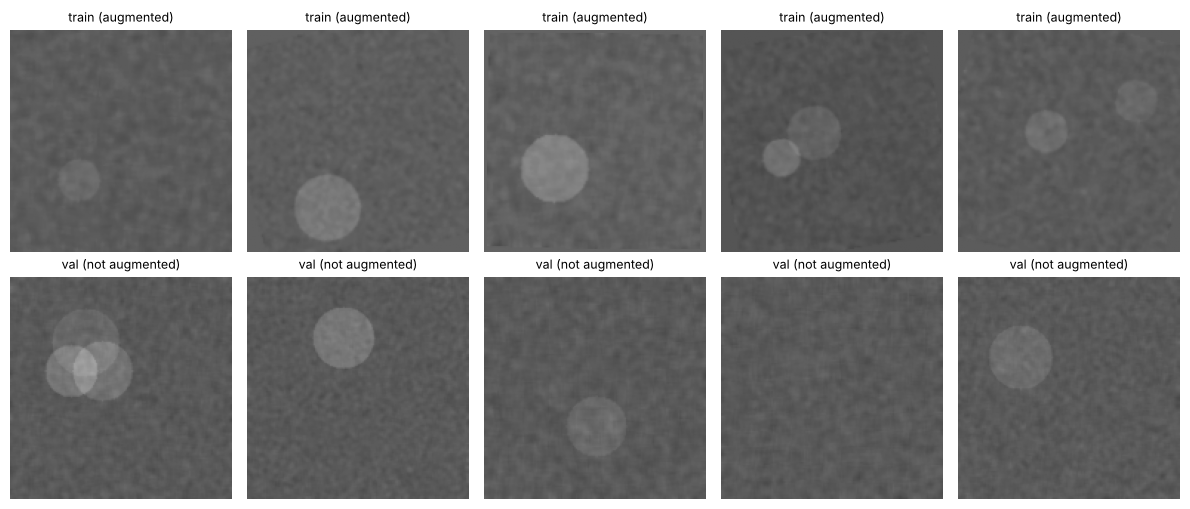

In [9]:
# Task 3d: sanity check - augmented training images (top) vs un-augmented validation images (bottom)
rng_viz = np.random.default_rng(SEED)
fig, axes = plt.subplots(2, 5, figsize=(12, 5.2))
for col in range(5):
    axes[0, col].imshow(load_and_preprocess(train_paths[col], augment=True, rng=rng_viz)[..., 0],
                        cmap="gray", vmin=0, vmax=1)
    axes[0, col].set_title("train (augmented)", fontsize=9); axes[0, col].axis("off")
    axes[1, col].imshow(load_and_preprocess(val_paths[col], augment=False)[..., 0],
                        cmap="gray", vmin=0, vmax=1)
    axes[1, col].set_title("val (not augmented)", fontsize=9); axes[1, col].axis("off")
plt.tight_layout()
plt.show()

In [10]:
# Task 3e: class weights from the ORIGINAL train label counts (before any augmentation)
weights = compute_class_weight("balanced", classes=np.array([0, 1]), y=np.array(train_labels))
class_weight_dict = {0: float(weights[0]), 1: float(weights[1])}
print("Class weights (NORMAL=0, PNEUMONIA=1):", class_weight_dict)

Class weights (NORMAL=0, PNEUMONIA=1): {0: 2.010752688172043, 1: 0.6654804270462633}


**Why the *original* counts?** Augmentation generates random variants on the fly; it does not change
how frequent each class is in reality. Weighting from counts that include augmented copies would
describe a distribution that does not exist. The weights make a NORMAL mistake cost roughly 3× a
PNEUMONIA mistake, which counteracts the 3:1 imbalance.

## Task 4 — Build the CNN (from scratch, no pretrained weights)

Conv2D learns local features, BatchNorm stabilises training, ReLU adds non-linearity, MaxPool
downsamples, Dropout fights overfitting on this small dataset, and the sigmoid gives P(PNEUMONIA).

In [11]:
def conv_block(filters):
    return [
        layers.Conv2D(filters, (3, 3), padding="same", use_bias=False),
        layers.BatchNormalization(momentum=0.9),
        layers.ReLU(),
        layers.MaxPooling2D((2, 2)),
    ]

model = models.Sequential(
    [layers.Input(shape=(IMG_SIZE, IMG_SIZE, 1))]
    + conv_block(32) + conv_block(64) + conv_block(128)          # 3 blocks, filters grow with depth
    + [
        layers.Flatten(),
        layers.Dropout(0.5),                                     # before the dense layers
        layers.Dense(128, activation="relu"),
        layers.Dense(1, activation="sigmoid"),                   # binary output
    ],
    name="chest_xray_cnn",
)
model.compile(optimizer="adam", loss="binary_crossentropy", metrics=["accuracy"])
model.summary()

Model: "chest_xray_cnn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 150, 150, 32)   │           288 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 150, 150, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu (ReLU)                    │ (None, 150, 150, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 75, 75, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 75, 75, 64)     │        18,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 75, 75, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_1 (ReLU)                  │ (None, 75, 75, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 37, 37, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 37, 37, 128)    │        73,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 37, 37, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_2 (ReLU)                  │ (None, 37, 37, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 18, 18, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 41472)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 41472)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     5,308,544 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 5,402,017 (20.61 MB)

 Trainable params: 5,401,569 (20.61 MB)

 Non-trainable params: 448 (1.75 KB)

## Task 5 — Train With the Right Settings

* `class_weight` (Task 3e) goes into `model.fit()`.
* `EarlyStopping` on `val_loss` (patience 4, restore best weights) decides the real cutoff.
* The epoch budget (25) is only a ceiling.

In [12]:
# Task 5a + 5b
EPOCHS = 25
early_stop = EarlyStopping(monitor="val_loss", patience=4, restore_best_weights=True)

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS,
    class_weight=class_weight_dict,
    callbacks=[early_stop],
    verbose=2,
)
print(f"\nTrained for {len(history.history['loss'])} epochs "
      f"(best val_loss = {min(history.history['val_loss']):.4f})")

Epoch 1/25


/usr/local/lib/python3.13/dist-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


/usr/local/lib/python3.13/dist-packages/keras/src/trainers/epoch_iterator.py:164: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


12/12 - 10s - 819ms/step - accuracy: 0.6738 - loss: 6.3164 - val_accuracy: 0.2576 - val_loss: 1.1081


Epoch 2/25


...

Epoch 9/25


12/12 - 17s - 1s/step - accuracy: 0.8342 - loss: 0.4191 - val_accuracy: 0.7121 - val_loss: 0.7483


Epoch 10/25


12/12 - 10s - 856ms/step - accuracy: 0.8717 - loss: 0.4290 - val_accuracy: 0.8636 - val_loss: 0.4674



Trained for 10 epochs (best val_loss = 0.4255)


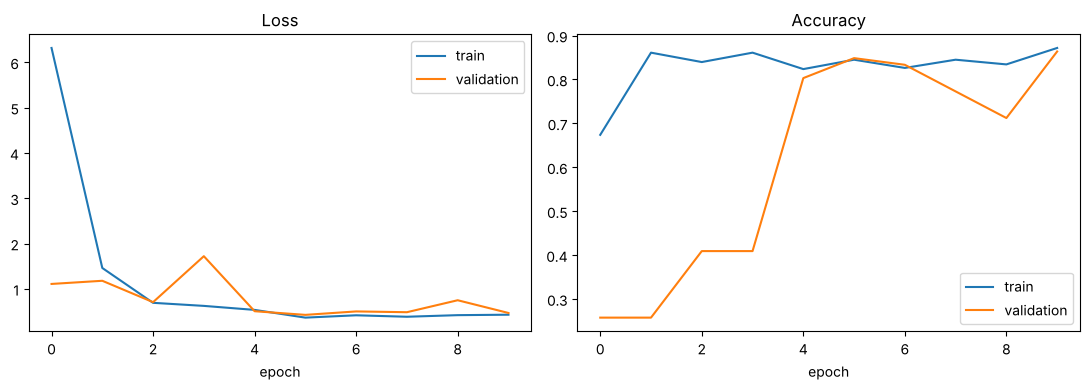

In [13]:
# Task 5c: training vs validation curves
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4))
ax1.plot(history.history["loss"], label="train")
ax1.plot(history.history["val_loss"], label="validation")
ax1.set_title("Loss"); ax1.set_xlabel("epoch"); ax1.legend()
ax2.plot(history.history["accuracy"], label="train")
ax2.plot(history.history["val_accuracy"], label="validation")
ax2.set_title("Accuracy"); ax2.set_xlabel("epoch"); ax2.legend()
plt.tight_layout()
plt.show()

## Task 6 — Evaluate Properly

A useless model that always predicts PNEUMONIA already beats 50 % accuracy on a PNEUMONIA-heavy test
set while never recognising a single NORMAL case. Per-class precision / recall / F1 expose that;
overall accuracy hides it.

In [14]:
# Task 6a: untouched test set (no augmentation, no shuffling -> predictions line up with labels)
test_paths, test_labels = [], []
for label, cls in enumerate(CLASSES):
    cls_dir = os.path.join(DATA_ROOT, "test", cls)
    for f in sorted(os.listdir(cls_dir)):
        test_paths.append(os.path.join(cls_dir, f))
        test_labels.append(label)

test_ds = build_dataset(test_paths, test_labels, augment=False)
print(f"Test images: {len(test_paths)}")

Test images: 120


In [15]:
# Task 6b: predictions + per-class report
y_true = np.array(test_labels)
y_prob = model.predict(test_ds, verbose=0).ravel()
y_pred = (y_prob >= 0.5).astype(int)

print(classification_report(y_true, y_pred, target_names=CLASSES, zero_division=0))
print(f"Accuracy: {(y_true == y_pred).mean():.3f}")
print(f"A useless 'always PNEUMONIA' model would score: {(y_true == 1).mean():.3f}")

              precision    recall  f1-score   support

      NORMAL       0.89      0.87      0.88        45
   PNEUMONIA       0.92      0.93      0.93        75

    accuracy                           0.91       120
   macro avg       0.90      0.90      0.90       120
weighted avg       0.91      0.91      0.91       120

Accuracy: 0.908
A useless 'always PNEUMONIA' model would score: 0.625


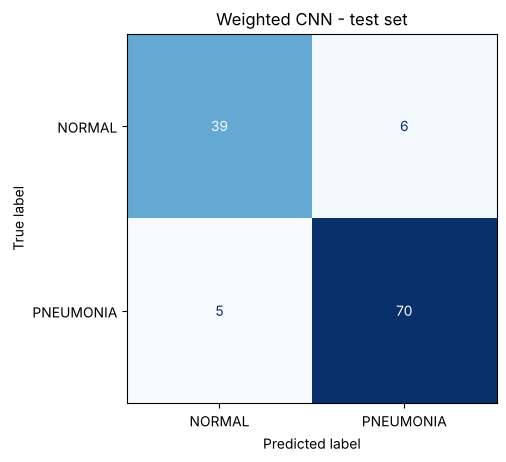

Recall on the NORMAL class:                      0.867
False negatives (real PNEUMONIA -> NORMAL):      5
False positives (real NORMAL -> PNEUMONIA):      6
The model makes more: false positives


In [16]:
# Task 6c: confusion matrix and the explicit questions
cm = confusion_matrix(y_true, y_pred, labels=[0, 1])
ConfusionMatrixDisplay(cm, display_labels=CLASSES).plot(cmap="Blues", colorbar=False)
plt.title("Weighted CNN - test set")
plt.show()

tn, fp, fn, tp = cm.ravel()
normal_recall = tn / (tn + fp)
print(f"Recall on the NORMAL class:                      {normal_recall:.3f}")
print(f"False negatives (real PNEUMONIA -> NORMAL):      {fn}")
print(f"False positives (real NORMAL -> PNEUMONIA):      {fp}")
print("The model makes more:", "false negatives" if fn > fp else "false positives" if fp > fn else "the same of each")

**Which error is worse?** In a medical setting a **false negative** is usually worse: a real pneumonia
case is missed and goes untreated, whereas a false positive normally costs only a follow-up check.
Class weighting trades some of one error for the other (it pushes the model towards recognising
NORMAL), so always read *both* recalls: NORMAL recall shows whether the imbalance is being handled,
and PNEUMONIA recall shows how many sick patients are still caught.

## Bonus 1 — Ablation: the same architecture WITHOUT class weights

Only one variable changes (class weighting) so any difference can be attributed to it.

Epoch 1/25


/usr/local/lib/python3.13/dist-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


/usr/local/lib/python3.13/dist-packages/keras/src/trainers/epoch_iterator.py:164: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


12/12 - 9s - 749ms/step - accuracy: 0.7166 - loss: 6.6131 - val_accuracy: 0.2727 - val_loss: 0.8996


Epoch 2/25


...

Epoch 8/25


12/12 - 10s - 817ms/step - accuracy: 0.8770 - loss: 0.2684 - val_accuracy: 0.8788 - val_loss: 0.3632


Epoch 9/25


12/12 - 7s - 606ms/step - accuracy: 0.8930 - loss: 0.2798 - val_accuracy: 0.8788 - val_loss: 0.4308


              precision    recall  f1-score   support

      NORMAL       0.97      0.76      0.85        45
   PNEUMONIA       0.87      0.99      0.93        75

    accuracy                           0.90       120
   macro avg       0.92      0.87      0.89       120
weighted avg       0.91      0.90      0.90       120



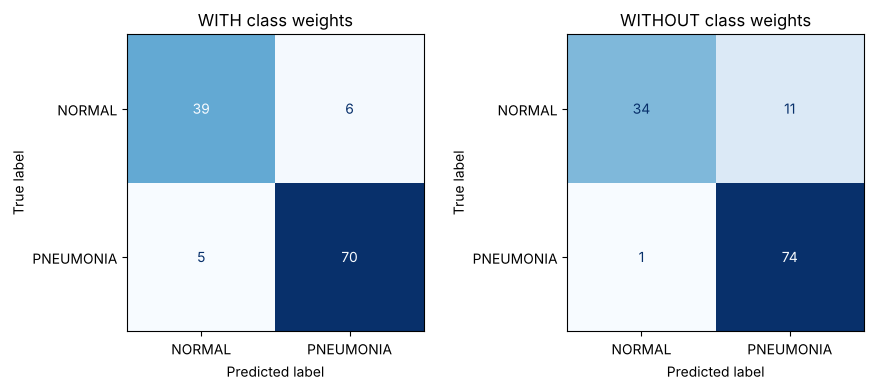

NORMAL recall   with weights: 0.867 | without: 0.756
False negatives with weights: 5 | without: 1
False positives with weights: 6 | without: 11


In [17]:
tf.keras.backend.clear_session()
tf.random.set_seed(SEED)
model_plain = models.clone_model(model)                  # same architecture, fresh random weights
model_plain.compile(optimizer="adam", loss="binary_crossentropy", metrics=["accuracy"])

history_plain = model_plain.fit(
    train_ds, validation_data=val_ds, epochs=EPOCHS,
    callbacks=[EarlyStopping(monitor="val_loss", patience=4, restore_best_weights=True)],
    verbose=2,                                           # note: NO class_weight here
)

y_pred_plain = (model_plain.predict(test_ds, verbose=0).ravel() >= 0.5).astype(int)
print(classification_report(y_true, y_pred_plain, target_names=CLASSES, zero_division=0))
cm_plain = confusion_matrix(y_true, y_pred_plain, labels=[0, 1])

fig, axes = plt.subplots(1, 2, figsize=(9, 4))
ConfusionMatrixDisplay(cm, display_labels=CLASSES).plot(ax=axes[0], cmap="Blues", colorbar=False)
axes[0].set_title("WITH class weights")
ConfusionMatrixDisplay(cm_plain, display_labels=CLASSES).plot(ax=axes[1], cmap="Blues", colorbar=False)
axes[1].set_title("WITHOUT class weights")
plt.tight_layout(); plt.show()

tn2, fp2, fn2, tp2 = cm_plain.ravel()
print(f"NORMAL recall   with weights: {normal_recall:.3f} | without: {tn2 / (tn2 + fp2):.3f}")
print(f"False negatives with weights: {fn} | without: {fn2}")
print(f"False positives with weights: {fp} | without: {fp2}")

## Bonus 2 — Frozen MobileNetV2 base + small head

Needs to download the ImageNet weights on first use, so this cell skips itself gracefully if the
download is not possible (e.g. offline).

In [18]:
import time
mobile_metrics = None
try:
    tf.keras.backend.clear_session()
    base = tf.keras.applications.MobileNetV2(input_shape=(IMG_SIZE, IMG_SIZE, 3),
                                             include_top=False, weights="imagenet")
    base.trainable = False                                # frozen pretrained weights

    inp = layers.Input(shape=(IMG_SIZE, IMG_SIZE, 1))
    x = layers.Concatenate()([inp, inp, inp])             # grayscale -> 3 channels
    x = layers.Rescaling(scale=2.0, offset=-1.0)(x)       # [0,1] -> [-1,1] as MobileNetV2 expects
    x = base(x, training=False)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dropout(0.3)(x)
    x = layers.Dense(64, activation="relu")(x)
    out = layers.Dense(1, activation="sigmoid")(x)
    mobile = models.Model(inp, out, name="mobilenetv2_transfer")
    mobile.compile(optimizer="adam", loss="binary_crossentropy", metrics=["accuracy"])

    t0 = time.time()
    mobile.fit(train_ds, validation_data=val_ds, epochs=EPOCHS, class_weight=class_weight_dict,
               callbacks=[EarlyStopping(monitor="val_loss", patience=4, restore_best_weights=True)],
               verbose=2)
    mobile_seconds = time.time() - t0

    y_pred_mobile = (mobile.predict(test_ds, verbose=0).ravel() >= 0.5).astype(int)
    print(classification_report(y_true, y_pred_mobile, target_names=CLASSES, zero_division=0))
    print(f"MobileNetV2 training time: {mobile_seconds:.0f}s")
    mobile_metrics = classification_report(y_true, y_pred_mobile, target_names=CLASSES,
                                           output_dict=True, zero_division=0)
except Exception as exc:
    print("Skipping the MobileNetV2 bonus:", type(exc).__name__, "-", str(exc)[:200])

/tmp/ipykernel_980/566006793.py:5: UserWarning: `input_shape` is undefined or non-square, or `rows` is not in [96, 128, 160, 192, 224]. Weights for input shape (224, 224) will be loaded as the default.
  base = tf.keras.applications.MobileNetV2(input_shape=(IMG_SIZE, IMG_SIZE, 3),


Skipping the MobileNetV2 bonus: Exception - URL fetch failure on https://storage.googleapis.com/tensorflow/keras-applications/mobilenet_v2/mobilenet_v2_weights_tf_dim_ordering_tf_kernels_1.0_224_no_top.h5: None -- Tunnel connection failed: 403 


## Writeup

In [19]:
from IPython.display import Markdown, display

rep = classification_report(y_true, y_pred, target_names=CLASSES, output_dict=True, zero_division=0)
rows = "\n".join(
    f"| {c} | {rep[c]['precision']:.3f} | {rep[c]['recall']:.3f} | {rep[c]['f1-score']:.3f} | {int(rep[c]['support'])} |"
    for c in CLASSES
)
nr_plain = tn2 / (tn2 + fp2)
data_note = ("> **These numbers come from the synthetic demo data, not real X-rays.**\n\n"
             if USE_SYNTHETIC else "")

display(Markdown(f"""
{data_note}### 1. Final test-set precision / recall / F1 per class

| Class | Precision | Recall | F1 | Support |
|---|---|---|---|---|
{rows}

Overall accuracy **{(y_true == y_pred).mean():.3f}** — but an always-PNEUMONIA model scores
{(y_true == 1).mean():.3f}, so the per-class numbers are what matter. NORMAL recall is **{normal_recall:.3f}**
with {fn} false negatives and {fp} false positives.

### 2. Did class weighting change the confusion matrix?

| | NORMAL recall | False negatives | False positives |
|---|---|---|---|
| With class weights | {normal_recall:.3f} | {fn} | {fp} |
| Without class weights | {nr_plain:.3f} | {fn2} | {fp2} |

Change in NORMAL recall from weighting: **{normal_recall - nr_plain:+.3f}**.

### 3. Something surprising about the preprocessing step

The raw training images come in **{len(sizes)} different sizes** and mixed colour modes ({modes}), so nothing can
even be batched until every image is resized and converted to grayscale. Order also matters: class weights
must come from the original label counts (imbalance {imbalance_ratio:.2f}x), and augmentation may only touch the
training set — otherwise the validation and test numbers stop describing real-world performance.
*(Draft — replace with your own observation after running on the real dataset.)*
"""))


> **These numbers come from the synthetic demo data, not real X-rays.**

### 1. Final test-set precision / recall / F1 per class

| Class | Precision | Recall | F1 | Support |
|---|---|---|---|---|
| NORMAL | 0.886 | 0.867 | 0.876 | 45 |
| PNEUMONIA | 0.921 | 0.933 | 0.927 | 75 |

Overall accuracy **0.908** — but an always-PNEUMONIA model scores
0.625, so the per-class numbers are what matter. NORMAL recall is **0.867**
with 5 false negatives and 6 false positives.

### 2. Did class weighting change the confusion matrix?

| | NORMAL recall | False negatives | False positives |
|---|---|---|---|
| With class weights | 0.867 | 5 | 6 |
| Without class weights | 0.756 | 1 | 11 |

Change in NORMAL recall from weighting: **+0.111**.

### 3. Something surprising about the preprocessing step

The raw training images come in **99 different sizes** and mixed colour modes ({'L': 290, 'RGB': 150}), so nothing can
even be batched until every image is resized and converted to grayscale. Order also matters: class weights
must come from the original label counts (imbalance 3.00x), and augmentation may only touch the
training set — otherwise the validation and test numbers stop describing real-world performance.
*(Draft — replace with your own observation after running on the real dataset.)*
